In [3]:
import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from pathlib import Path

DIRETORIO_C = Path("./results/c")
DIRETORIO_KORNIA = Path("./results/kornia")

# Imagens que serão analisadas
arquivos_c = sorted(DIRETORIO_C.glob("*.pgm"))

print(f"Imagens encontradas: {len(arquivos_c)}")

Imagens encontradas: 12


In [4]:
def comparar_imagens(arquivo_c, arquivo_kornia):

    imagem_c = cv2.imread(
        str(arquivo_c),
        cv2.IMREAD_GRAYSCALE
    )

    imagem_kornia = cv2.imread(
        str(arquivo_kornia),
        cv2.IMREAD_GRAYSCALE
    )

    if imagem_c is None:
        raise RuntimeError(f"Erro ao abrir: {arquivo_c}")

    if imagem_kornia is None:
        raise RuntimeError(f"Erro ao abrir: {arquivo_kornia}")

    if imagem_c.shape != imagem_kornia.shape:
        raise ValueError(
            f"Dimensões diferentes: "
            f"{imagem_c.shape} vs {imagem_kornia.shape}"
        )

    # Converter para float para evitar overflow
    c = imagem_c.astype(np.float64)
    kornia = imagem_kornia.astype(np.float64)

    # Diferença
    diferenca = kornia - c
    diferenca_abs = np.abs(diferenca)

    # Métricas
    total_pixels = diferenca.size

    pixels_iguais = np.sum(diferenca == 0)

    pixels_diferentes = np.sum(diferenca != 0)

    percentual_iguais = (
        pixels_iguais / total_pixels * 100
    )

    mae = np.mean(diferenca_abs)

    mse = np.mean(diferenca ** 2)

    rmse = np.sqrt(mse)

    erro_maximo = np.max(diferenca_abs)

    # PSNR
    if mse == 0:
        psnr = float("inf")
    else:
        psnr = 10 * np.log10((255 ** 2) / mse)

    return {
        "imagem": arquivo_c.name,
        "largura": imagem_c.shape[1],
        "altura": imagem_c.shape[0],
        "pixels": total_pixels,
        "iguais": pixels_iguais,
        "diferentes": pixels_diferentes,
        "% iguais": percentual_iguais,
        "MAE": mae,
        "MSE": mse,
        "RMSE": rmse,
        "Erro máximo": erro_maximo,
        "PSNR (dB)": psnr,
        "imagem_c": imagem_c,
        "imagem_kornia": imagem_kornia,
        "diferenca": diferenca,
        "diferenca_abs": diferenca_abs,
    }

In [5]:
resultados = []

for arquivo_c in arquivos_c:

    arquivo_kornia = DIRETORIO_KORNIA / arquivo_c.name

    if not arquivo_kornia.exists():
        print(f"⚠️ Não encontrada no Kornia: {arquivo_c.name}")
        continue

    resultado = comparar_imagens(
        arquivo_c,
        arquivo_kornia
    )

    resultados.append(resultado)

print(f"Testes realizados: {len(resultados)}")

Testes realizados: 12


In [6]:
df = pd.DataFrame([
    {
        "Imagem": r["imagem"],
        "Dimensão": f'{r["largura"]}×{r["altura"]}',
        "Pixels": r["pixels"],
        "Pixels diferentes": r["diferentes"],
        "% iguais": r["% iguais"],
        "MAE": r["MAE"],
        "RMSE": r["RMSE"],
        "Erro máximo": r["Erro máximo"],
        "PSNR (dB)": r["PSNR (dB)"],
    }
    for r in resultados
])

df

,Imagem,Dimensão,Pixels,Pixels diferentes,% iguais,MAE,RMSE,Erro máximo,PSNR (dB)
0,barb_result.pgm,512×512,262144,0,100.0,0.0,0.0,0.0,inf
1,boat_result.pgm,512×512,262144,0,100.0,0.0,0.0,0.0,inf
2,france_result.pgm,672×496,333312,0,100.0,0.0,0.0,0.0,inf
3,frog_result.pgm,621×498,309258,0,100.0,0.0,0.0,0.0,inf
4,goldhill2_result.pgm,512×512,262144,0,100.0,0.0,0.0,0.0,inf
5,lena2_result.pgm,512×512,262144,0,100.0,0.0,0.0,0.0,inf
6,library_result.pgm,464×352,163328,0,100.0,0.0,0.0,0.0,inf
7,mandrill_result.pgm,512×512,262144,0,100.0,0.0,0.0,0.0,inf
8,mountain_result.pgm,640×480,307200,0,100.0,0.0,0.0,0.0,inf
9,peppers2_result.pgm,512×512,262144,0,100.0,0.0,0.0,0.0,inf


In [7]:
total_pixels = sum(r["pixels"] for r in resultados)

total_iguais = sum(r["iguais"] for r in resultados)

total_diferentes = sum(
    r["diferentes"] for r in resultados
)

compatibilidade_global = (
    total_iguais / total_pixels * 100
)

print("==============================================")
print("           RESUMO DA VALIDAÇÃO")
print("==============================================")

print(f"Imagens testadas:       {len(resultados)}")
print(f"Total de pixels:        {total_pixels:,}")
print(f"Pixels iguais:          {total_iguais:,}")
print(f"Pixels diferentes:     {total_diferentes:,}")

print(
    f"Compatibilidade:        "
    f"{compatibilidade_global:.6f}%"
)

print(
    f"Maior erro encontrado:  "
    f"{max(r['Erro máximo'] for r in resultados)}"
)

print(
    f"Maior MAE:              "
    f"{max(r['MAE'] for r in resultados):.6f}"
)

print(
    f"Maior RMSE:             "
    f"{max(r['RMSE'] for r in resultados):.6f}"
)

           RESUMO DA VALIDAÇÃO
Imagens testadas:       12
Total de pixels:        3,210,250
Pixels iguais:          3,210,250
Pixels diferentes:     0
Compatibilidade:        100.000000%
Maior erro encontrado:  0.0
Maior MAE:              0.000000
Maior RMSE:             0.000000


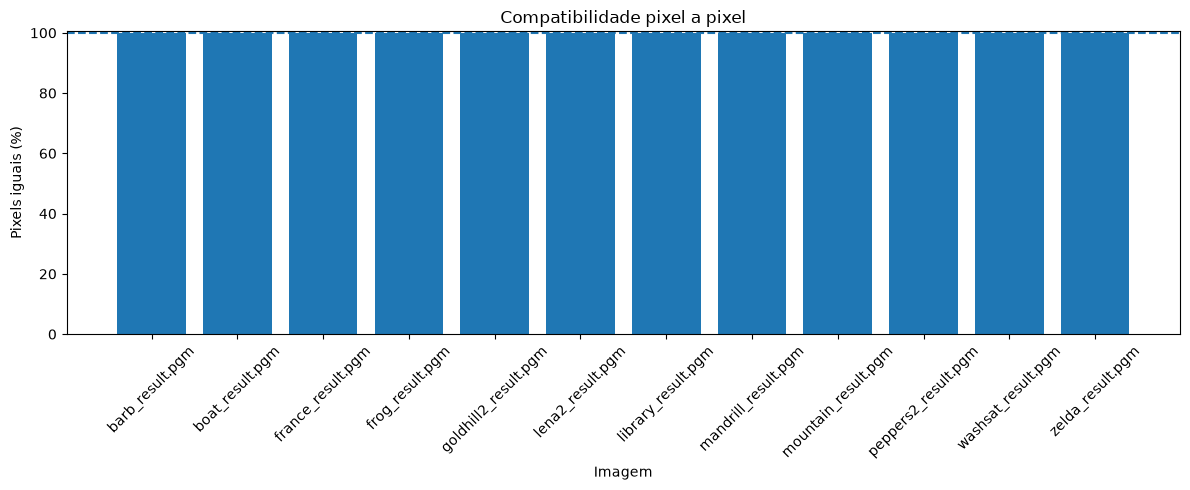

In [8]:
plt.figure(figsize=(12, 5))

plt.bar(
    df["Imagem"],
    df["% iguais"]
)

plt.axhline(
    100,
    linestyle="--"
)

plt.ylabel("Pixels iguais (%)")
plt.xlabel("Imagem")
plt.title("Compatibilidade pixel a pixel")

plt.xticks(rotation=45)
plt.ylim(0, 100.5)

plt.tight_layout()
plt.show()

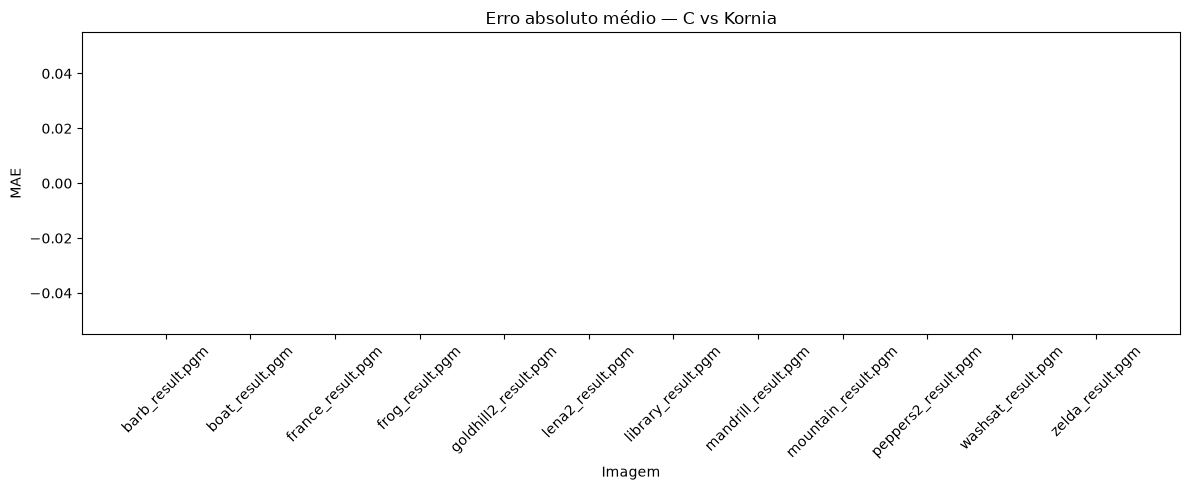

In [9]:
plt.figure(figsize=(12, 5))

plt.bar(
    df["Imagem"],
    df["MAE"]
)

plt.ylabel("MAE")
plt.xlabel("Imagem")
plt.title("Erro absoluto médio — C vs Kornia")

plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

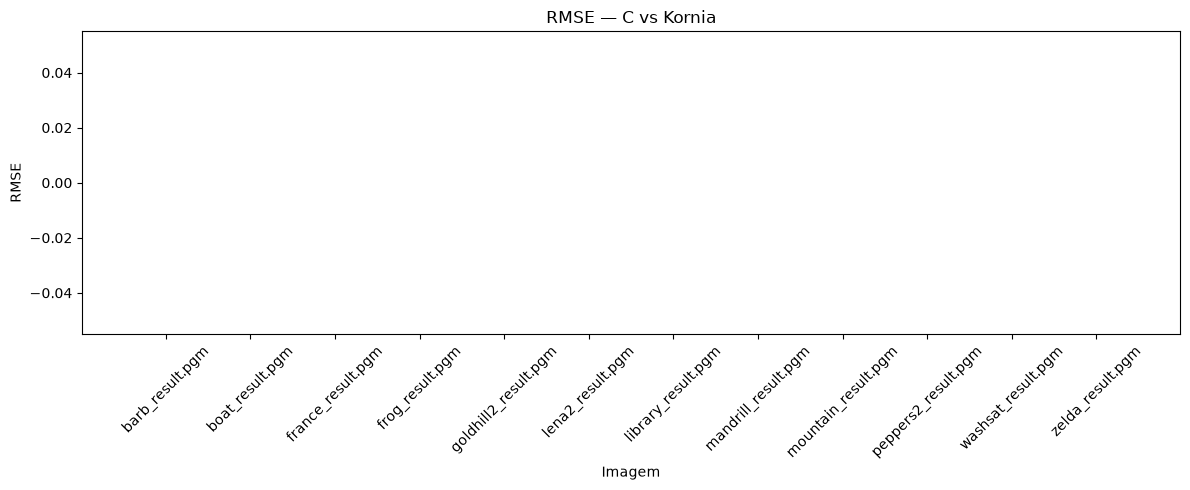

In [10]:
plt.figure(figsize=(12, 5))

plt.bar(
    df["Imagem"],
    df["RMSE"]
)

plt.ylabel("RMSE")
plt.xlabel("Imagem")
plt.title("RMSE — C vs Kornia")

plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

/home/antonio/Documentos/projetos/unsharp-masking/.venv/lib/python3.12/site-packages/matplotlib/transforms.py:2496: RuntimeWarning: invalid value encountered in dot
  return Affine2D(np.dot(self._b.get_affine().get_matrix(),


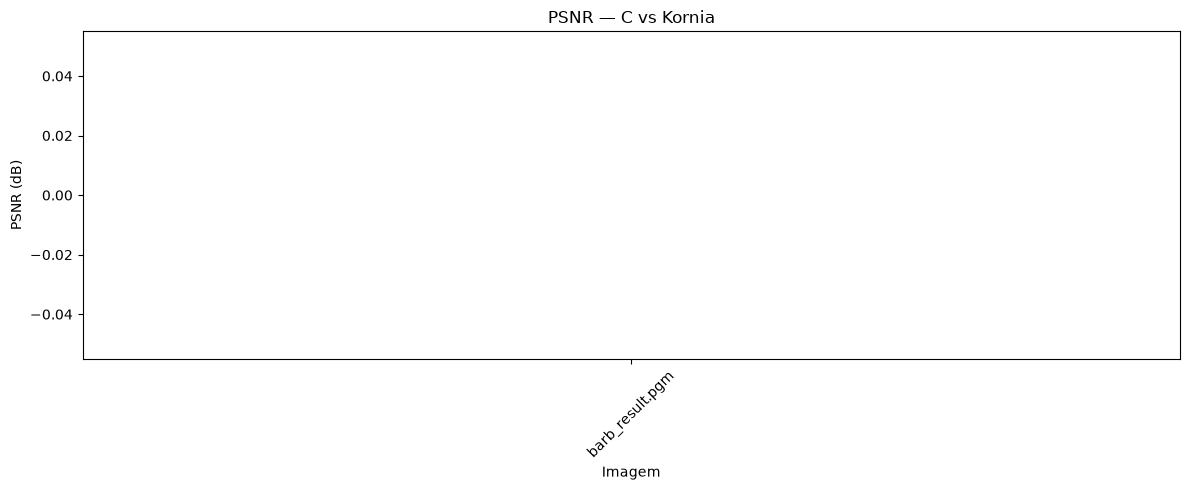

In [11]:
plt.figure(figsize=(12, 5))

plt.bar(
    df["Imagem"],
    df["PSNR (dB)"]
)

plt.ylabel("PSNR (dB)")
plt.xlabel("Imagem")
plt.title("PSNR — C vs Kornia")

plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

In [ ]:
indice = 0

r = resultados[indice]

print(r["imagem"])

plt.figure(figsize=(12, 5))

plt.imshow(r["imagem_c"], cmap="gray")

plt.title(f'C — {r["imagem"]}')

plt.axis("off")

plt.show()

plt.figure(figsize=(12, 5))

plt.imshow(r["imagem_kornia"], cmap="gray")

plt.title(f'Kornia — {r["imagem"]}')

plt.axis("off")

plt.show()

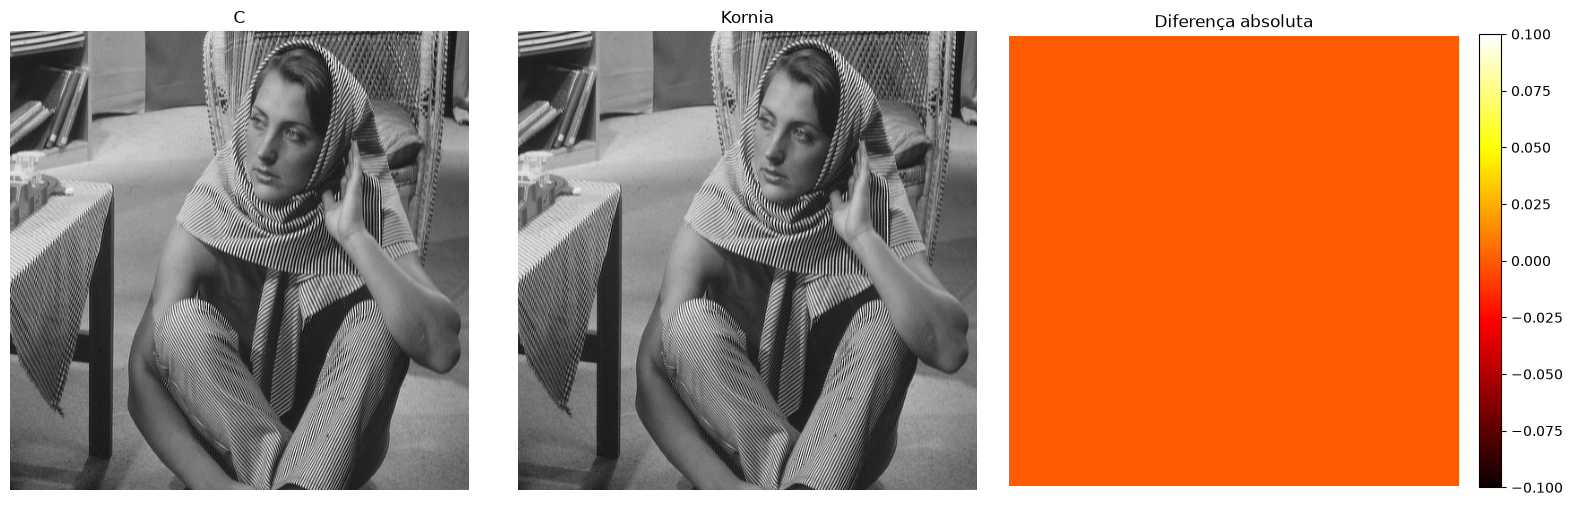

In [16]:
fig, axes = plt.subplots(
    1,
    3,
    figsize=(16, 5)
)

axes[0].imshow(
    r["imagem_c"],
    cmap="gray"
)

axes[0].set_title("C")

axes[1].imshow(
    r["imagem_kornia"],
    cmap="gray"
)

axes[1].set_title("Kornia")

im = axes[2].imshow(
    r["diferenca_abs"],
    cmap="hot"
)

axes[2].set_title("Diferença absoluta")

fig.colorbar(
    im,
    ax=axes[2],
    fraction=0.046,
    pad=0.04
)

for ax in axes:
    ax.axis("off")

plt.tight_layout()
plt.show()